# Part A: What is a hit?

This notebook walks through Part A step by step. Every heavy lifting function lives in `src/nextaaa/`

| Section | Question from the brief | Deck slide |
|---|---|---|
| 1 | Setup and data | (appendix) |
| 2 | What is the highest rated movie in 2023? How do we balance ratings and votes? | 01, 02 |
| 3 | Who was the most popular actor in 2023? | 03 |
| 4 | Define a metric that captures a "hit movie" | 04 to 07 |
| 5 | Trends in user-movie preferences over the years | 08 to 11 |
| 6 | Summary and hand-off to Part B | |

Set `DEMO = True` in the next cell to run everything on small synthetic data in under a minute. That checks your setup. Then set it back to `False` for the real analysis. Demo numbers are fake: never put them in the deck.

## 1. Setup

In [1]:
DEMO = False  # True = small synthetic data, for checking your setup only

import logging, sys
from dataclasses import replace
from pathlib import Path

import pandas as pd
from IPython.display import display

# Find the project root (the folder containing src/nextaaa), wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "nextaaa").exists())
sys.path.insert(0, str(ROOT / "src"))  # lets us import nextaaa without pip install

from nextaaa import clustering, features, io_imdb, movielens, plots, popularity, ratings, trends
from nextaaa.config import AnalysisConfig, Paths

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
pd.set_option("display.max_columns", 30, "display.width", 160, "display.float_format", "{:,.3f}".format)

In [3]:
cfg = AnalysisConfig()  # every tunable number, documented in src/nextaaa/config.py

if DEMO:
    from nextaaa.synthetic import make_synthetic_imdb, make_synthetic_movielens
    demo = ROOT / "data" / "synthetic"
    if not (demo / "imdb" / "title.basics.tsv.gz").exists():
        make_synthetic_imdb(demo / "imdb")
        make_synthetic_movielens(demo / "imdb", demo / "ml-20m")
    paths = Paths.resolve(demo / "imdb", demo / "ml-20m", demo / "cache", ROOT / "outputs_demo")
    cfg = replace(cfg, min_votes_for_clustering=200, movielens_min_ratings_per_year=500,
                  movielens_min_ratings_for_std=20, dbscan_min_samples=10)
else:
    # Defaults: data/imdb, data/ml-20m, data/cache, outputs (or set NEXTAAA_* env vars)
    paths = Paths.resolve()

paths.make_output_dirs()
paths

Paths(imdb_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/imdb'), movielens_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/ml-20m'), cache_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/data/cache'), output_dir=WindowsPath('C:/Users/user/Documents/next-aaa-title-part-a/next-aaa-title/outputs'))

### Load IMDb

`load_movies` streams the big gzipped files in chunks, keeps only feature films, and caches the result. **The first real run takes a few minutes; later runs take seconds.**

It also handles three traps in IMDb's files: missing values written as `\N`, quote characters inside titles, and films literally titled "NA" (pandas would silently turn those into missing values).

What counts as a movie (all set in `config.py`): `titleType == "movie"`, not adult, runtime of at least 60 minutes (or unknown), a known release year, and at least one rating.

In [7]:
movies = io_imdb.load_movies(paths, cfg)
print(f"{len(movies):,} rated feature films")
movies.sample(5, random_state=1)

INFO nextaaa._cache: Building title_basics (this can take a few minutes the first time)...
INFO nextaaa._cache: Cached 760,683 rows to title_basics__e914106aea.parquet
INFO nextaaa._cache: Building title_ratings (this can take a few minutes the first time)...
INFO nextaaa._cache: Cached 1,725,891 rows to title_ratings__noparams.parquet
INFO nextaaa.io_imdb: Movie table: 327,437 rated feature films


327,437 rated feature films


,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres,averageRating,numVotes
112256,tt0336688,movie,Kejarlah Daku Kau Kutangkap,0,1989,95,"Comedy,Drama",7.900,75
251447,tt32552636,movie,Semeynyy prizrak,0,2025,84,"Comedy,Family,Fantasy",4.600,99
185084,tt1543800,movie,Sergej in der Urne,0,2010,105,"Biography,Documentary,Family",7.200,9
84038,tt0202365,movie,A Crime in the Quiet Neighborhood,0,1967,105,"Crime,Thriller",5.700,46
236066,tt2832470,movie,Dead Snow 2: Red vs. Dead,0,2014,100,"Action,Comedy,Horror",6.800,28912


In [9]:
# Quick sanity check: how are ratings and votes distributed?
movies[["averageRating", "numVotes", "runtimeMinutes"]].describe(percentiles=[.1, .5, .9, .99])

,averageRating,numVotes,runtimeMinutes
count,"327,437.000","327,437.000","298,261.000"
mean,6.126,"3,978.205",97.348
std,1.376,"39,577.549",140.450
min,1.000,5.000,60.000
10%,4.300,12.000,73.000
50%,6.200,72.000,92.000
90%,7.800,"2,052.000",124.000
99%,9.000,"80,759.840",170.000
max,10.000,"3,257,990.000","51,420.000"


**What to notice:** `numVotes` is extremely skewed. The median film has a few dozen to a few hundred votes, while the top 1% have hundreds of thousands. That skew is why we (a) need shrinkage to rank films, and (b) use `log10(votes)` rather than raw votes for clustering.

## 2. Highest rated movie of 2023, and balancing rating vs. votes

**Is `averageRating` already balanced?** No. IMDb's `averageRating` is *weighted* to resist vote-stuffing, but not *shrunk* by vote count: a film with 12 votes can still show 9.4.

**The fix** is IMDb's own Top 250 formula, a Bayesian average:

$$\text{shrunk} = \frac{v}{v+m}\,R \;+\; \frac{m}{v+m}\,C$$

- $R$ = the film's rating, $v$ = its votes
- $C$ = the average rating of the comparison pool (all 2023 films)
- $m$ = "how many votes before we trust a film's own rating"; we use the 90th percentile of 2023 vote counts

**Read it as a tug of war.** With few votes, the film is pulled to the average $C$. With many votes, it keeps its own rating. At exactly $v = m$ votes it lands halfway.

Here is the worked example from our discussion:

In [11]:
for label, R, v in [("Obscure festival film", 9.4, 12), ("Major release", 8.6, 900_000)]:
    print(f"{label:22s} rating {R}  votes {v:>9,}  ->  shrunk {ratings.weighted_rating(R, v, m=25_000, C=6.2):.2f}")

Obscure festival film  rating 9.4  votes        12  ->  shrunk 6.20
Major release          rating 8.6  votes   900,000  ->  shrunk 8.54


In [13]:
board, info = ratings.top_rated(movies, cfg.target_year, cfg.shrinkage_quantile,
                                cfg.min_votes_target_year, top_n=15)
print(f"Pool: {info['pool_size']:,} films of {info['year']} with >= {info['min_votes']} votes | "
      f"m = {info['m']:,.0f} votes, C = {info['C']:.2f}")
board

Pool: 5,197 films of 2023 with >= 100 votes | m = 6,163 votes, C = 5.81


,rank_shrunk,primaryTitle,averageRating,numVotes,shrunk_rating,rank_raw,genres,tconst
0,1,12th Fail,8.700,179116,8.604,59,"Biography,Drama",tt23849204
1,2,Spider-Man: Across the Spider-Verse,8.500,560025,8.471,88,"Action,Adventure,Animation",tt9362722
2,3,20 Days in Mariupol,8.600,65995,8.362,70,"Documentary,War",tt24082438
3,4,Oppenheimer,8.200,1108296,8.187,148,"Biography,Drama,History",tt15398776
4,5,Lost Ladies,8.300,62679,8.078,130,"Comedy,Drama",tt21626284
5,6,Guardians of the Galaxy Vol. 3,7.900,492024,7.874,229,"Action,Adventure,Comedy",tt6791350
6,7,The Holdovers,7.900,275587,7.854,229,"Comedy,Drama",tt14849194
7,8,Hi Nanna,8.300,27817,7.849,130,"Drama,Family,Romance",tt25433734
8,9,Perfect Days,7.900,114001,7.793,229,Drama,tt27503384
9,10,Past Lives,7.800,179505,7.734,277,"Drama,Romance",tt13238346


**How to read the table:** `rank_shrunk` is our ranking. `rank_raw` is where the film would sit on raw `averageRating` alone. Big differences between the two columns are the whole argument for shrinkage: they are low-vote films the raw average over-rewards.

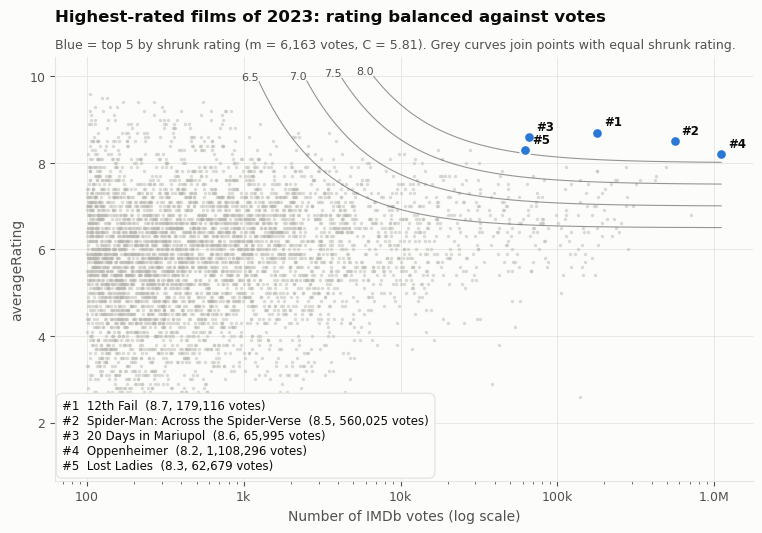

In [15]:
fig = plots.plot_rating_vs_votes(movies, info, board)
plots.save(fig, paths.figures_dir / f"01_rating_vs_votes_{cfg.target_year}.png")
fig

**Slide talking point:** each grey curve joins films with the same shrunk rating. A film with 2,000 votes has to be rated far higher than a film with 500,000 votes to reach the same curve. This is the "balance between ratings and number of votes", shown rather than told.

### Does the answer depend on our choice of m?

$m$ is a judgement call, so we test it. The bump chart recomputes the ranking for $m$ from the 50th to the 99th percentile of votes.

,quantile,m,primaryTitle,shrunk_rating
12,0.500,467.000,12th Fail,8.692
34,0.600,717.600,12th Fail,8.688
56,0.700,"1,142.200",12th Fail,8.682
78,0.800,"2,153.000",12th Fail,8.666
100,0.900,"6,163.000",12th Fail,8.604
122,0.950,"16,238.600",12th Fail,8.460
152,0.990,"135,473.880",Spider-Man: Across the Spider-Verse,7.977


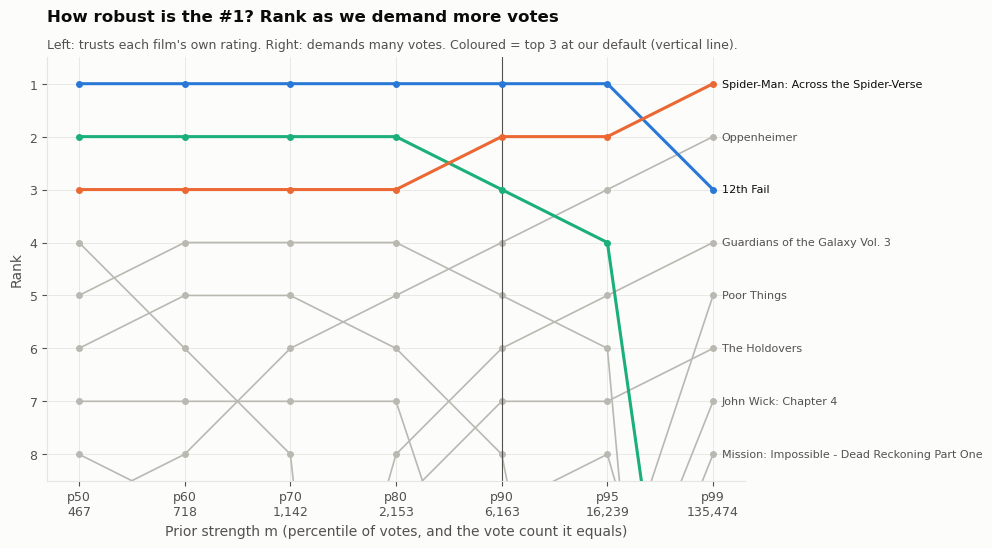

In [17]:
sens = ratings.sensitivity_to_m(movies, cfg.target_year, cfg.sensitivity_quantiles, cfg.min_votes_target_year)
fig = plots.plot_m_sensitivity(sens, cfg.shrinkage_quantile)
plots.save(fig, paths.figures_dir / f"02_m_sensitivity_{cfg.target_year}.png")
display(sens[sens["rank"] == 1][["quantile", "m", "primaryTitle", "shrunk_rating"]])
fig

**How to read it:** if the same film is #1 across most of the range, say so: "the answer is robust to how strict we are". If the #1 flips at small $m$, explain that small $m$ trusts tiny audiences, which is exactly the bias we wanted to remove.

## 3. Most popular actor of 2023: two definitions, side by side

Both sum over the actor's 2023 films, with a **billing weight** $1/\sqrt{\text{rank}}$ so a lead counts more than a cameo (lead 1.00, 2nd 0.71, 4th 0.50):

- **Reach** = Σ billing weight × votes. *How many people engaged with this actor's work?*
- **Net goodwill** = Σ billing weight × votes × (shrunk rating − 2023 average). *Did they engage **and** like it?* Films rated below average subtract goodwill.

Why not simply votes × rating? Ratings vary from about 5 to 8.5 while votes vary 1,000-fold, so multiplying by the raw rating barely changes the order. Using the rating *above average* lets quality genuinely matter.

The first run parses `title.principals` (about 100 million rows), which takes several minutes; it is cached afterwards.

In [19]:
credits = io_imdb.load_actor_credits(paths, cfg, set(movies["tconst"]))
year_ids = set(movies.loc[movies["startYear"] == cfg.target_year, "tconst"])
names = io_imdb.load_names(paths, set(credits.loc[credits["tconst"].isin(year_ids), "nconst"]))

pop = popularity.actor_popularity(movies, credits, names, cfg.target_year, cfg.shrinkage_quantile,
                                  cfg.billing_weight_power, cfg.min_votes_target_year)
popularity.side_by_side(pop, top_n=10)

INFO nextaaa._cache: Building actor_credits (this can take a few minutes the first time)...
INFO nextaaa._cache: Cached 2,559,208 rows to actor_credits__3ad3a72935.parquet
INFO nextaaa._cache: Building names (this can take a few minutes the first time)...
INFO nextaaa._cache: Cached 66,020 rows to names__fd57c5653b.parquet


,Reach: actor,Reach: weighted votes,Reach: top film,Goodwill: actor,Goodwill: score,Goodwill: top film
rank,,,,,,
1,Cillian Murphy,"1,110,247.000",Oppenheimer,Cillian Murphy,"2,629,464.967",Oppenheimer
2,Emily Blunt,"840,426.617",Oppenheimer,Emily Blunt,"1,899,145.139",Oppenheimer
3,Matt Damon,"840,043.994",Oppenheimer,Matt Damon,"1,825,670.285",Oppenheimer
4,Chris Pratt,"796,124.768",Guardians of the Galaxy Vol. 3,Shameik Moore,"1,487,444.017",Spider-Man: Across the Spider-Verse
5,Margot Robbie,"709,508.000",Barbie,Chris Pratt,"1,366,463.369",Guardians of the Galaxy Vol. 3
6,Alden Ehrenreich,"621,036.285",Oppenheimer,Robert Downey Jr.,"1,314,477.927",Oppenheimer
7,Issa Rae,"607,633.372",Barbie,Alden Ehrenreich,"1,200,760.068",Oppenheimer
8,Shameik Moore,"560,025.000",Spider-Man: Across the Spider-Verse,Scott Grimes,"1,073,266.733",Oppenheimer
9,Robert Downey Jr.,"554,148.000",Oppenheimer,Hailee Steinfeld,"1,051,781.751",Spider-Man: Across the Spider-Verse


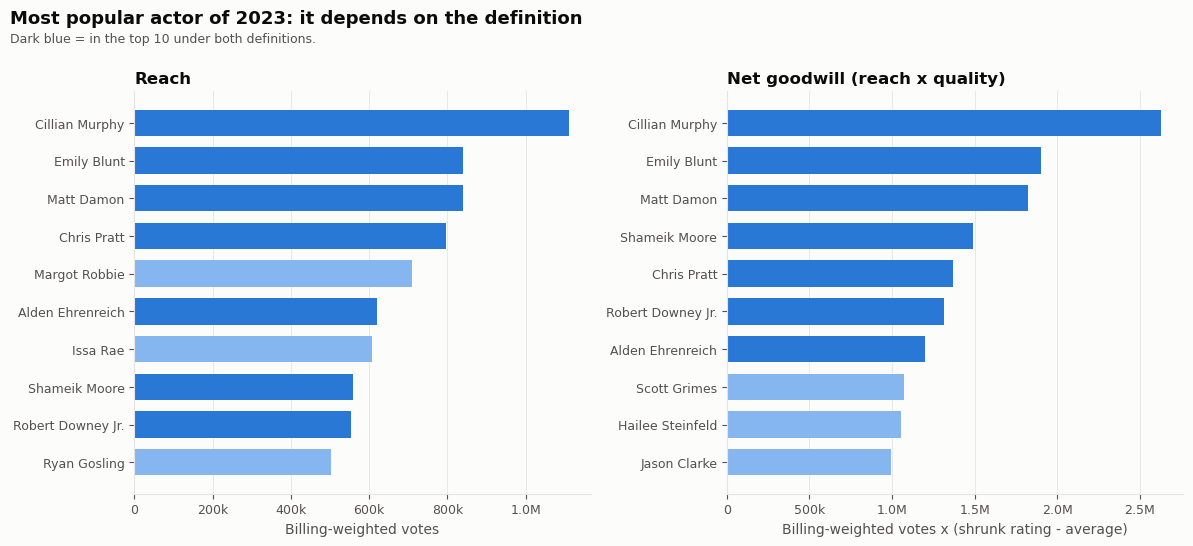

In [21]:
fig = plots.plot_actor_side_by_side(pop, cfg.target_year)
plots.save(fig, paths.figures_dir / f"03_actors_{cfg.target_year}.png")
fig

**Slide talking point:** for a studio, *Reach* answers "who brings an audience?" and *Net goodwill* answers "whose films audiences are glad they watched?". An actor high on both is the safer casting bet; an actor high on reach but low on goodwill draws crowds to films people don't love.

## 4. Defining a "hit": clustering on quality × reach

### 4.1 The two axes

- **Quality** = raw `averageRating`, only for films with at least 1,000 votes (so the rating is stable). We do **not** cluster on the shrunk rating, because shrinkage pulls low-vote films to the average and would erase the *Hidden Gem* quadrant.
- **Reach** = `reach_z`, the film's log-votes compared with **other films released the same year**: $\text{reach\_z} = (\log_{10} v - \text{median}_{year}) / (\text{IQR}_{year}/1.349)$. Zero means a typical film of its year; 2 means far more votes than typical. Without this, "hit" would just mean "released 2005 to 2015", the years with the most accumulated votes.

Both are then standardised so KMeans and DBSCAN weigh them equally.

In [23]:
frame = features.build_cluster_frame(movies, cfg)
X = features.feature_matrix(frame)
print(f"{len(frame):,} films, {frame.startYear.min()}-{frame.startYear.max()}")

# Proof the year-adjustment works: raw log-votes drift with year, reach_z does not.
by_decade = frame.assign(decade=frame.startYear // 10 * 10).groupby("decade")[["log_votes", "reach_z"]].median()
by_decade

INFO nextaaa.features: Clustering universe: 46,129 films, 1950-2025


46,129 films, 1950-2025


,log_votes,reach_z
decade,,
1950,3.398,0.000
1960,3.451,0.000
1970,3.446,0.000
1980,3.573,0.000
1990,3.701,0.000
2000,3.613,0.000
2010,3.523,0.000
2020,3.474,0.000


### 4.2 How many clusters? Elbow method + silhouette score

- **Elbow:** inertia (total squared distance of films to their cluster centre) always falls as k grows. The *elbow* is where adding another cluster stops buying much. We detect it automatically with the Kneedle method (Satopää et al., 2011).
- **Silhouette** (Rousseeuw, 1987): for each film, how much closer it is to its own cluster than to the next one, from −1 to 1. Rough guide: above 0.5 = clear structure; 0.25 to 0.5 = weak but real; below 0.25 = little natural structure.

C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

,k,inertia,silhouette
0,2,"56,715.757",0.400
1,3,"33,236.658",0.414
2,4,"26,680.018",0.350
3,5,"21,335.280",0.352
4,6,"17,949.180",0.354
5,7,"15,586.340",0.337
6,8,"13,805.415",0.341


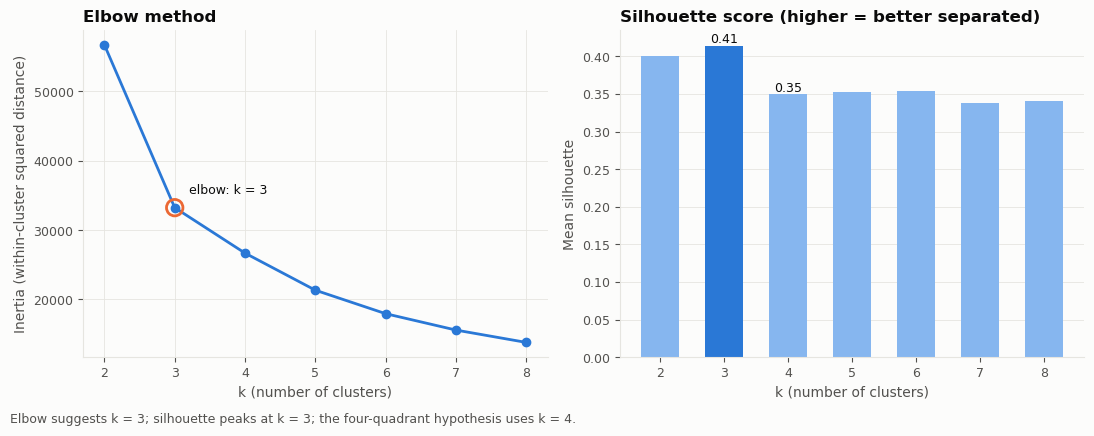

In [26]:
diag = clustering.kmeans_diagnostics(X, cfg.k_range, cfg.silhouette_sample_size, cfg.random_state)
fig = plots.plot_elbow_silhouette(diag.table, diag.k_elbow, diag.k_silhouette, cfg.k_hypothesis)
plots.save(fig, paths.figures_dir / "04_elbow_silhouette.png")
display(diag.table)
fig

**How to read and present this (be ready for the data scientists):**

- If the elbow lands on **4**, the data supports the four-quadrant hypothesis.
- If it lands elsewhere (2 or 3 is common on this kind of data), say so plainly: the data is one continuous cloud, and the quadrants are a *useful business lens* we impose, not groups that nature drew. That honesty earns trust.
- Moderate silhouette scores (around 0.3 to 0.4) are normal here. That is the reason we don't rely on KMeans alone, and combine three methods below.

To try another k, change `K` in the next cell (or run the script with `--k 3`).

In [28]:
K = cfg.k_hypothesis  # 4 = Hit / Hidden Gem / Loser / Popular but Divisive

### 4.3 DBSCAN: choosing eps with the k-distance plot

DBSCAN (Ester et al., 1996) needs no k. It needs `min_samples` (how many neighbours make a region "dense") and `eps` (the neighbourhood radius). The standard recipe: sort every film's distance to its `min_samples`-th neighbour and pick `eps` at the **knee**, where the flat "dense" part turns into the steep "sparse" part.

Suggested eps = 0.128


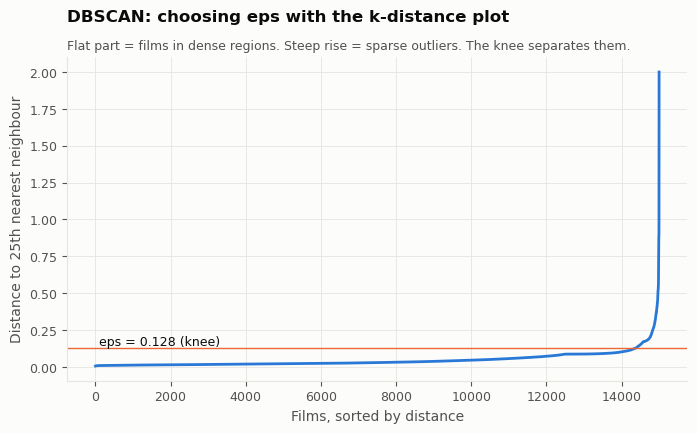

In [30]:
kdist = clustering.k_distance_curve(X, cfg.dbscan_min_samples, cfg.silhouette_sample_size, cfg.random_state)
eps = clustering.suggest_eps(kdist)
fig = plots.plot_k_distance(kdist, eps, cfg.dbscan_min_samples)
plots.save(fig, paths.figures_dir / "05_k_distance.png")
print(f"Suggested eps = {eps:.3f}")
fig

### 4.4 Run all three methods and take a majority vote

1. **KMeans** with k = `K`. Clusters are named by matching their centres to the four quadrant corners (Hungarian algorithm, so no name is used twice).
2. **DBSCAN** as an outlier detector: films in dense regions are *Typical*; noise points are *Exceptional*, named by their quadrant. **DBSCAN tells us who is exceptional; the quadrant tells us how.**
3. **Median split** as the no-algorithm baseline.

`is_hit` = at least 2 of the 3 call the film a hit. **Mega-hit** = a hit that DBSCAN also flags as exceptional: the AAA-grade tier.

In [32]:
res = clustering.run_clustering(frame, X, cfg, k=K)
labelled = res.frame
print("DBSCAN silhouettes:", {k: round(v, 3) for k, v in res.dbscan_silhouette.items()})
display(res.eps_sweep)
display(res.agreement)

INFO nextaaa.clustering: KMeans k=2  inertia=56716  silhouette=0.400
INFO nextaaa.clustering: KMeans k=3  inertia=33237  silhouette=0.414
INFO nextaaa.clustering: KMeans k=4  inertia=26680  silhouette=0.350
INFO nextaaa.clustering: KMeans k=5  inertia=21335  silhouette=0.352
INFO nextaaa.clustering: KMeans k=6  inertia=17949  silhouette=0.354
INFO nextaaa.clustering: KMeans k=7  inertia=15586  silhouette=0.337
INFO nextaaa.clustering: KMeans k=8  inertia=13805  silhouette=0.341
INFO nextaaa.clustering: Elbow suggests k=3, silhouette suggests k=3; using k=4.
INFO nextaaa.clustering: DBSCAN eps=0.128: 2 clusters, 2.7% noise


DBSCAN silhouettes: {'non_noise': 0.536, 'core_vs_outliers': 0.479}


,eps,n_clusters,noise_share
0,0.064,95,0.181
1,0.096,4,0.050
2,0.128,2,0.027
3,0.192,1,0.009
4,0.257,1,0.005


,pair,cohen_kappa,pct_agree
0,hit_kmeans vs hit_dbscan,0.062,0.798
1,hit_kmeans vs hit_quadrant,0.471,0.801
2,hit_dbscan vs hit_quadrant,0.045,0.724
3,cluster_kmeans vs quadrant_median (ARI),0.359,NaN


**How to read the agreement table:** Cohen's kappa is agreement corrected for chance (1 = perfect, 0 = chance). We use it instead of "% agree" because hits are rare: two methods that both say "not a hit" to everything would still agree 85% of the time. The eps sweep shows DBSCAN's sensitivity: smaller eps = more films flagged as outliers.

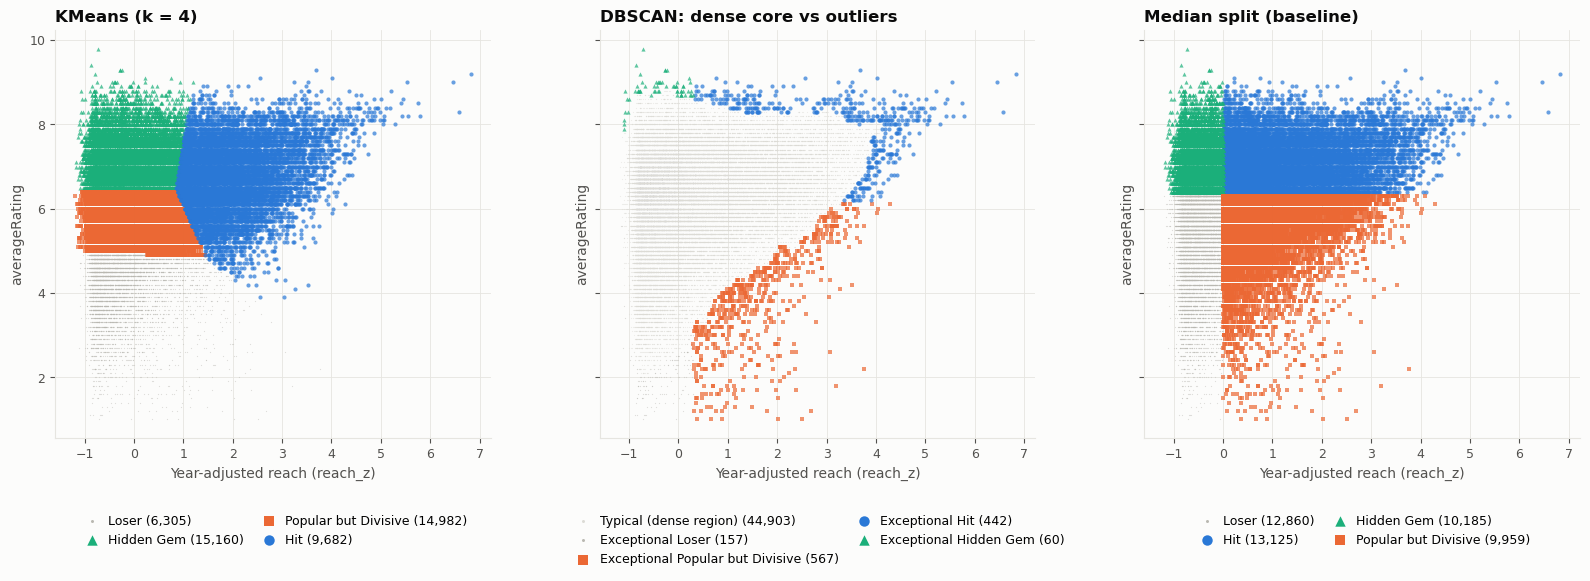

In [34]:
fig = plots.plot_cluster_maps(labelled, res.k_used)
plots.save(fig, paths.figures_dir / "06_cluster_maps.png")
fig

In [35]:
for col in ["cluster_kmeans", "hit_tier"]:
    display(clustering.cluster_profile(labelled, col))

,films,share_pct,median_rating,median_votes,median_reach_pct,examples (most voted)
cluster_kmeans,,,,,,
Hidden Gem,15160,32.860,7.000,"2,596.500",41.460,Hoop Dreams; Death and the Maiden; The Last Se...
Hit,9682,20.990,6.800,"45,110.000",89.480,The Shawshank Redemption; The Dark Knight; Inc...
Popular but Divisive,14982,32.480,5.800,"2,509.000",40.380,"Honey, I Blew Up the Kid; The Santa Clause 3: ..."
Loser,6305,13.670,4.300,"2,068.000",33.250,Snow White; Batman & Robin; Radhe


,films,share_pct,median_rating,median_votes,median_reach_pct,examples (most voted)
hit_tier,,,,,,
Mega-hit,442,0.960,8.300,"308,012.500",99.170,The Shawshank Redemption; The Dark Knight; Inc...
Hit,6444,13.970,7.100,"43,387.000",89.600,Avatar; Titanic; The Truman Show
Not a hit,39243,85.070,6.200,"2,679.000",42.620,Suicide Squad; Spider-Man 3; Twilight


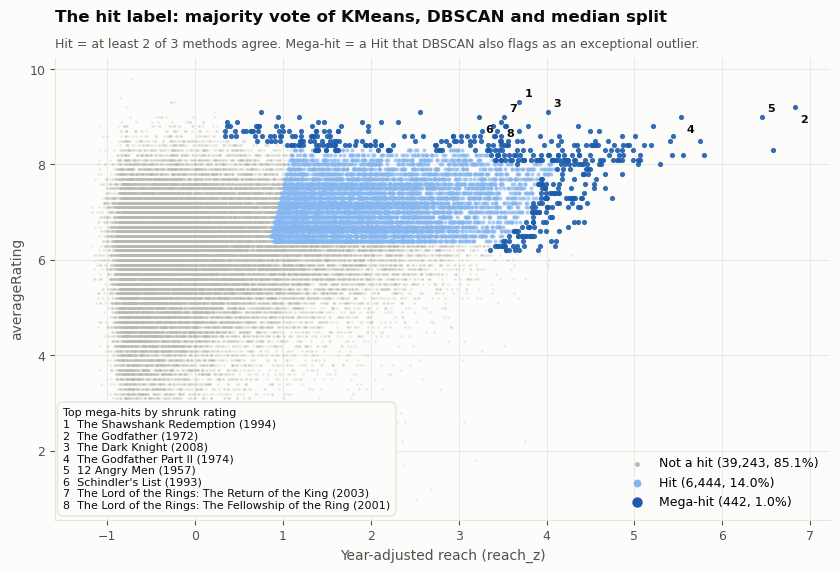

In [40]:
fig = plots.plot_hit_tiers(labelled)
plots.save(fig, paths.figures_dir / "07_hit_tiers.png")
fig

**Slide talking point (why this metric suits a studio head):** a hit has to be **both** liked and widely seen *for its time*. Liked but unseen is a Hidden Gem (great film, marketing problem). Seen but disliked is Popular but Divisive (opening weekend, no legs, no sequel). A AAA investment needs the top-right corner, and the Mega-hit tier is the bar for a franchise-level bet.

Save the labels: Part B (the model that proposes the next AAA title) learns from them.

In [42]:
keep = ["tconst", "primaryTitle", "startYear", "genres", "runtimeMinutes", "averageRating", "numVotes",
        "reach_z", "reach_pct", "shrunk_rating", "cluster_kmeans", "cluster_dbscan", "quadrant_median",
        "hit_kmeans", "hit_dbscan", "hit_quadrant", "hit_votes", "is_hit", "hit_tier"]
labelled[keep].to_csv(paths.tables_dir / "hit_labels.csv", index=False)
labelled[keep].to_pickle(paths.cache_dir / "hit_labels.pkl")
labelled[keep].query("hit_tier == 'Mega-hit'").nlargest(15, "shrunk_rating")

,tconst,primaryTitle,startYear,genres,runtimeMinutes,averageRating,numVotes,reach_z,reach_pct,shrunk_rating,cluster_kmeans,cluster_dbscan,quadrant_median,hit_kmeans,hit_dbscan,hit_quadrant,hit_votes,is_hit,hit_tier
10716,tt0111161,The Shawshank Redemption,1994,Drama,142,9.300,3257990,3.686,100.000,9.236,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
4124,tt0068646,The Godfather,1972,"Crime,Drama",175,9.200,2268352,6.829,100.000,9.182,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
18795,tt0468569,The Dark Knight,2008,"Crime,Thriller",152,9.100,3243979,4.012,100.000,9.023,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
4627,tt0071562,The Godfather Part II,1974,"Crime,Drama",202,9.000,1521308,5.535,100.000,8.969,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
1052,tt0050083,12 Angry Men,1957,"Crime,Drama",96,9.000,1009660,6.453,100.000,8.964,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
10289,tt0108052,Schindler's List,1993,"Biography,Drama,History",196,9.000,1610975,3.233,100.000,8.895,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
13087,tt0167260,The Lord of the Rings: The Return of the King,2003,"Adventure,Drama,Fantasy",201,9.000,2204006,3.517,100.000,8.883,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
12195,tt0120737,The Lord of the Rings: The Fellowship of the Ring,2001,"Adventure,Drama,Fantasy",178,8.900,2248098,3.481,100.000,8.789,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
2695,tt0060196,"The Good, the Bad and the Ugly",1966,"Adventure,Drama,Western",178,8.800,905487,5.207,100.000,8.756,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit
10514,tt0109830,Forrest Gump,1994,"Drama,Romance",142,8.800,2548477,3.539,99.745,8.732,Hit,Exceptional Hit,Hit,True,True,True,3,True,Mega-hit


## 5. Trends in audience preferences over the years

### 5.1 IMDb: supply vs. demand by genre

For each genre and year: the share of **films made** (grey) vs. the share of **audience votes** (blue). Blue above grey = audiences want more of that genre than studios make. A film tagged "Action,Adventure,Sci-Fi" counts 1/3 towards each genre, so shares add to 100%. Lines are 5-year rolling means.

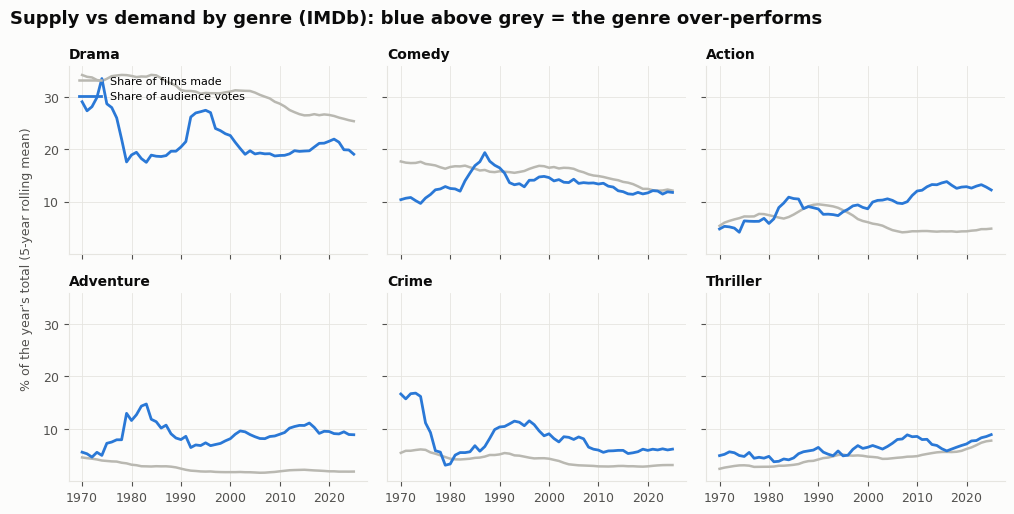

In [44]:
imdb_tr = trends.imdb_genre_trends(movies, cfg)
fig = plots.plot_imdb_genre_trends(imdb_tr)
plots.save(fig, paths.figures_dir / "08_imdb_genre_trends.png")
fig

In [46]:
# Which genres over-perform most in the last 10 years? (vote share minus film share)
recent = imdb_tr[imdb_tr["year"] >= cfg.max_year - 9]
(recent.assign(gap=recent.vote_share - recent.film_share)
       .groupby("genre")[["film_share", "vote_share", "gap"]].mean().sort_values("gap", ascending=False))

,film_share,vote_share,gap
genre,,,
Action,4.532,12.923,8.392
Adventure,1.943,9.292,7.349
Crime,2.956,5.924,2.968
Thriller,6.501,7.409,0.908
Comedy,12.558,11.639,-0.919
Drama,26.185,20.549,-5.635
Other,45.325,32.264,-13.062


### 5.2 MovieLens 20M: what users actually rated (1995 to 2015)

Skipped automatically if MovieLens is not in `data/ml-20m`. MovieLens 20M ends in March 2015, so the partial year 2015 is dropped from yearly counts.

In [ ]:
ml = movielens.load_movielens(paths)
if ml is None:
    print("MovieLens not found; skipping 5.2 and 5.3.")
else:
    ml_tr = trends.movielens_genre_trends(ml, cfg, cfg.movielens_min_ratings_per_year)
    yearly = trends.movielens_yearly_summary(ml, cfg.movielens_min_ratings_per_year)
    fig_genre = plots.plot_movielens_genre_trends(ml_tr)
    plots.save(fig_genre, paths.figures_dir / "09_movielens_genre_trends.png")
    fig_yearly = plots.plot_movielens_yearly(yearly)
    plots.save(fig_yearly, paths.figures_dir / "10_movielens_yearly.png")
    display(yearly)
    display(fig_genre)
    display(fig_yearly)

**How to read the yearly panels:** *median film age* rising means users increasingly rate older catalogue titles (the "nostalgia gap"); *top 1% share* falling means attention spreads across more films (a longer tail), rising means blockbusters dominate.

### 5.3 Is "Popular but Divisive" really divisive?

IMDb only publishes averages. MovieLens has every individual rating, so for films in both datasets we can measure the **spread** of opinion. If the hypothesis holds, Popular but Divisive films should have a wider spread than Hits.

In [ ]:
if ml is not None:
    spread = trends.rating_spread_by_cluster(ml, labelled, "cluster_kmeans", cfg.movielens_min_ratings_for_std)
    display(spread.groupby("cluster_kmeans")["rating_std"].describe())
    if len(spread):
        fig = plots.plot_divisiveness(spread, "cluster_kmeans")
        plots.save(fig, paths.figures_dir / "11_divisiveness_check.png")
        display(fig)

## 6. Summary and hand-off

What Part A produced:

- **Highest-rated 2023 film** by shrunk rating, with a robustness check over $m$.
- **Most popular 2023 actor** under two definitions, side by side.
- **A hit metric**: KMeans + DBSCAN + median split, majority vote, with a Mega-hit tier. Saved to `outputs/tables/hit_labels.csv` and `data/cache/hit_labels.pkl`.
- **Trends**: supply vs. demand by genre (IMDb) and user behaviour over time (MovieLens).

**Next (Part B):** the generate → score → refine loop. Azure OpenAI generates candidate concepts; a separate scorer, trained on these hit labels with only pre-release features (runtime, genre, director and cast track record, franchise flag), estimates each concept's chance of being a hit.

Everything in this notebook can also be run in one go: `python scripts/run_part_a.py`.